# EXP-004: Testing the SNR hypothesis -- does 'reduce' eventually win as label-flip rate approaches 0.5?

**Status: engineering validation / proof of concept**, same caveats as prior notebooks.

**Purpose**: EXP-003 found "increase" beats "reduce" for label noise at flip_prob=0.35,
unlike gradient-noise instability where "reduce" won decisively. Hypothesis proposed
in EXP-003's interpretation: the real governing variable may be the SIGNAL-TO-NOISE
RATIO of the corrupted gradient, not a clean "drift vs instability" category. At
flip_prob=0.35, ~65% of labels are still correct -- the average gradient direction
stays net-informative. As flip_prob -> 0.5, the informative signal should shrink
toward zero (at exactly 0.5, labels carry no information about the true class at
all). **Prediction to test**: "reduce" should start winning somewhere as flip_prob
climbs toward 0.5, if the SNR hypothesis is right.

**Design**: sweep flip_prob over a fine grid from mild to the boundary of pure noise
(0.05 to 0.49), holding everything else identical to EXP-003 (same toy task, same
reduce/increase/auto_grad definitions). At each level, measure peak_loss and
steady_state_loss for reduce vs. increase (arm C only, to keep this tractable), and
plot the peak_loss/steady_state_loss DIFFERENCE (reduce - increase) against flip_prob
-- a crossover from positive (increase wins) to negative (reduce wins) would confirm
the hypothesis; if it never crosses, the hypothesis is wrong (or the crossover point
is beyond where labels remain informative at all, i.e. the hypothesis is vacuous).


In [1]:
import numpy as np
import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt

torch.set_num_threads(1)
print("torch", torch.__version__, "| numpy", np.__version__)


C:\Users\USER\anaconda3\Lib\site-packages\torch\cuda\__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


torch 2.5.1+cpu | numpy 2.0.2


## 1. Toy task, disturbance, diagnostic (same as EXP-003, flip_prob now swept)

In [2]:
def make_model(seed):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 1))

MEAN0_BASE = np.array([-1.0, -1.0])
MEAN1_BASE = np.array([1.0, 1.0])
BASE_NOISE_SCALE = 0.5

def gen_batch(rng, flip_prob=0.0, batch_size=16):
    y_true = rng.integers(0, 2, size=batch_size)
    means = np.where(y_true[:, None] == 0, MEAN0_BASE, MEAN1_BASE)
    x = means + rng.normal(scale=BASE_NOISE_SCALE, size=(batch_size, 2))
    flip_mask = rng.random(batch_size) < flip_prob
    y_observed = np.where(flip_mask, 1 - y_true, y_true)
    return torch.tensor(x, dtype=torch.float32), torch.tensor(y_observed, dtype=torch.float32)

def grad_norm(model):
    total = 0.0
    for p in model.parameters():
        if p.grad is not None:
            total += float((p.grad.detach() ** 2).sum())
    return total ** 0.5

N_STEPS = 400
DISTURBANCE_ONSET = 200
RAMP_LEN = 40
STEADY_STATE_WINDOW = 100
WARMUP = 50
TREND_WINDOW = 5
COOLDOWN = 30
LR_REDUCTION_FACTOR = 0.3
LR_BOOST_FACTOR = 3.0
GRAD_RATIO_SENSITIVITY = 1.5

def _ramp(step):
    if step < DISTURBANCE_ONSET:
        return 0.0
    return min(step - DISTURBANCE_ONSET, RAMP_LEN) / RAMP_LEN

def _instant(step):
    return 1.0 if step >= DISTURBANCE_ONSET else 0.0

def make_label_noise_fns(max_flip_prob):
    def forecastable(step):
        return max_flip_prob * _ramp(step)
    def unforecastable(step):
        return max_flip_prob * _instant(step)
    return forecastable, unforecastable

def auto_select_intervention_grad(loss_window, gradnorm_window, baseline_loss_mean, baseline_gradnorm_mean,
                                   sensitivity=GRAD_RATIO_SENSITIVITY):
    loss_ratio = (float(np.mean(loss_window)) + 1e-6) / (baseline_loss_mean + 1e-6)
    gradnorm_ratio = (float(np.mean(gradnorm_window)) + 1e-6) / (baseline_gradnorm_mean + 1e-6)
    return "reduce" if gradnorm_ratio > sensitivity * loss_ratio else "increase"


## 2. Single training run (arm C only, reduce/increase/auto_grad)

In [3]:
def run_trial(seed, disturbance_fn, intervention_type):
    assert intervention_type in ("reduce", "increase", "auto_grad")
    rng = np.random.default_rng(seed)
    model = make_model(seed)
    opt = torch.optim.SGD(model.parameters(), lr=0.1)
    loss_fn = nn.BCEWithLogitsLoss()

    loss_hist, gradnorm_hist = [], []
    trigger_step = None
    cooldown_remaining = 0
    base_lr = 0.1
    active_intervention = None
    threshold = baseline_loss_mean = baseline_gradnorm_mean = None

    for step in range(N_STEPS):
        flip_prob = disturbance_fn(step)
        xb, yb = gen_batch(rng, flip_prob=flip_prob)

        opt.zero_grad()
        hidden = model[1](model[0](xb))
        logits = model[2](hidden).squeeze(-1)
        loss = loss_fn(logits, yb)
        loss.backward()

        loss_t = float(loss.item())
        gn_t = grad_norm(model)
        loss_hist.append(loss_t)
        gradnorm_hist.append(gn_t)

        if step == WARMUP:
            warm_loss = np.array(loss_hist[:WARMUP])
            threshold = float(warm_loss.mean() + 3 * warm_loss.std() + 1e-6)
            baseline_loss_mean = float(warm_loss.mean())
            baseline_gradnorm_mean = float(np.mean(gradnorm_hist[:WARMUP]))

        if step >= WARMUP and trigger_step is None and loss_t > threshold:
            trigger_step = step
            cooldown_remaining = COOLDOWN
            if intervention_type == "auto_grad":
                loss_window = loss_hist[max(0, step - TREND_WINDOW + 1):step + 1]
                gradnorm_window = gradnorm_hist[max(0, step - TREND_WINDOW + 1):step + 1]
                active_intervention = auto_select_intervention_grad(
                    loss_window, gradnorm_window, baseline_loss_mean, baseline_gradnorm_mean)
            else:
                active_intervention = intervention_type

        if cooldown_remaining > 0:
            factor = LR_REDUCTION_FACTOR if active_intervention == "reduce" else LR_BOOST_FACTOR
            for g in opt.param_groups:
                g["lr"] = base_lr * factor
            cooldown_remaining -= 1
        else:
            for g in opt.param_groups:
                g["lr"] = base_lr

        opt.step()

    loss_arr = np.array(loss_hist)
    peak_loss = float(loss_arr[DISTURBANCE_ONSET:].max())
    steady_state_loss = float(np.mean(loss_arr[-STEADY_STATE_WINDOW:]))
    return {
        "trigger_step": trigger_step, "active_intervention": active_intervention,
        "peak_loss": peak_loss, "steady_state_loss": steady_state_loss,
    }


## 3. Sweep flip_prob from mild to near-pure-noise

In [4]:
SEEDS = list(range(10))
FLIP_PROBS = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.48, 0.49]

results = []
for flip_prob in FLIP_PROBS:
    fc, uf = make_label_noise_fns(flip_prob)
    for cond_name, fn in (("forecastable", fc), ("unforecastable", uf)):
        for itype in ("reduce", "increase", "auto_grad"):
            for seed in SEEDS:
                r = run_trial(seed, fn, itype)
                results.append({
                    "flip_prob": flip_prob, "condition": cond_name, "intervention": itype, "seed": seed,
                    "trigger_step": r["trigger_step"], "active_intervention": r["active_intervention"],
                    "peak_loss": r["peak_loss"], "steady_state_loss": r["steady_state_loss"],
                })

df = pd.DataFrame(results)
print(f"Total trials: {len(df)}")
df.head(10)


Total trials: 660


,flip_prob,condition,intervention,seed,trigger_step,active_intervention,peak_loss,steady_state_loss
0,0.05,forecastable,reduce,0,230,reduce,0.977461,0.210606
1,0.05,forecastable,reduce,1,233,reduce,0.978517,0.232123
2,0.05,forecastable,reduce,2,334,reduce,0.865647,0.231062
3,0.05,forecastable,reduce,3,345,reduce,0.908319,0.244267
4,0.05,forecastable,reduce,4,220,reduce,0.997857,0.200533
5,0.05,forecastable,reduce,5,233,reduce,0.970564,0.223629
6,0.05,forecastable,reduce,6,231,reduce,1.174845,0.233476
7,0.05,forecastable,reduce,7,243,reduce,0.879687,0.226748
8,0.05,forecastable,reduce,8,223,reduce,1.440433,0.249101
9,0.05,forecastable,reduce,9,228,reduce,1.313914,0.240143


## 4. Crossover analysis: reduce - increase, by flip_prob

In [5]:
summary = df.groupby(["flip_prob", "condition", "intervention"]).agg(
    n_triggered=("trigger_step", lambda s: s.notna().sum()),
    mean_peak_loss=("peak_loss", "mean"),
    mean_steady_state_loss=("steady_state_loss", "mean"),
).round(4)

def get(flip_prob, cond, itype, col):
    return summary.loc[(flip_prob, cond, itype), col]

rows = []
for fp in FLIP_PROBS:
    peak_reduce = get(fp, "forecastable", "reduce", "mean_peak_loss")
    peak_increase = get(fp, "forecastable", "increase", "mean_peak_loss")
    ss_reduce = get(fp, "unforecastable", "reduce", "mean_steady_state_loss")
    ss_increase = get(fp, "unforecastable", "increase", "mean_steady_state_loss")
    auto_rows = df[(df["flip_prob"] == fp) & (df["intervention"] == "auto_grad") & df["trigger_step"].notna()]
    auto_reduce_frac = (auto_rows["active_intervention"] == "reduce").mean() if len(auto_rows) else float("nan")
    rows.append({
        "flip_prob": fp,
        "peak_diff_reduce_minus_increase": peak_reduce - peak_increase,
        "steady_diff_reduce_minus_increase": ss_reduce - ss_increase,
        "auto_grad_frac_chose_reduce": auto_reduce_frac,
    })
crossover = pd.DataFrame(rows)
crossover


,flip_prob,peak_diff_reduce_minus_increase,steady_diff_reduce_minus_increase,auto_grad_frac_chose_reduce
0,0.05,0.0837,0.0014,0.0
1,0.10,0.2458,0.0010,0.0
2,0.15,0.2618,0.0008,0.0
3,0.20,0.5139,0.0005,0.0
4,0.25,0.6971,0.0003,0.0
5,0.30,0.7734,0.0003,0.0
6,0.35,0.7593,0.0003,0.0
7,0.40,0.9420,0.0005,0.0
8,0.45,0.9644,0.0005,0.0
9,0.48,0.9458,0.0006,0.0


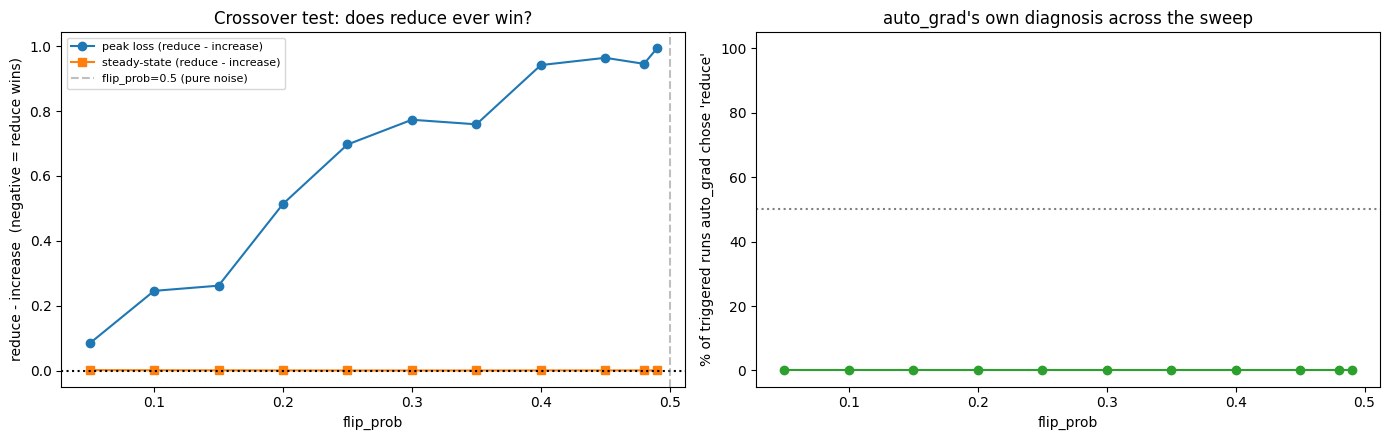

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(crossover["flip_prob"], crossover["peak_diff_reduce_minus_increase"], marker="o", label="peak loss (reduce - increase)")
axes[0].plot(crossover["flip_prob"], crossover["steady_diff_reduce_minus_increase"], marker="s", label="steady-state (reduce - increase)")
axes[0].axhline(0, color="black", linestyle=":")
axes[0].axvline(0.5, color="gray", linestyle="--", alpha=0.5, label="flip_prob=0.5 (pure noise)")
axes[0].set_xlabel("flip_prob")
axes[0].set_ylabel("reduce - increase  (negative = reduce wins)")
axes[0].set_title("Crossover test: does reduce ever win?")
axes[0].legend(fontsize=8)

axes[1].plot(crossover["flip_prob"], crossover["auto_grad_frac_chose_reduce"] * 100, marker="o", color="tab:green")
axes[1].axhline(50, color="gray", linestyle=":")
axes[1].set_xlabel("flip_prob")
axes[1].set_ylabel("% of triggered runs auto_grad chose 'reduce'")
axes[1].set_title("auto_grad's own diagnosis across the sweep")
axes[1].set_ylim(-5, 105)

plt.tight_layout()
plt.savefig("exp_label_noise_snr_sweep.png", dpi=120)
plt.show()


## 5. Interpretation

In [7]:
peak_crosses = (crossover["peak_diff_reduce_minus_increase"] < 0).any()
steady_crosses = (crossover["steady_diff_reduce_minus_increase"] < 0).any()

peak_cross_fp = crossover.loc[crossover["peak_diff_reduce_minus_increase"] < 0, "flip_prob"].min() if peak_crosses else None
steady_cross_fp = crossover.loc[crossover["steady_diff_reduce_minus_increase"] < 0, "flip_prob"].min() if steady_crosses else None

interpretation = f'''
SNR HYPOTHESIS TEST: does "reduce" ever start winning as flip_prob -> 0.5?

Peak loss:     {"YES -- reduce first wins at flip_prob=" + f"{peak_cross_fp}" if peak_crosses else "NO -- increase wins (or ties) at every flip_prob tested, up to 0.49"}
Steady-state:  {"YES -- reduce first wins at flip_prob=" + f"{steady_cross_fp}" if steady_crosses else "NO -- increase wins (or ties) at every flip_prob tested, up to 0.49"}

Full crossover table:
{crossover.round(4).to_string(index=False)}

VERDICT: {"The SNR hypothesis is SUPPORTED -- as the informative fraction of labels shrinks toward chance level, reduce eventually becomes the better choice, consistent with the idea that the real governing variable is how much genuine signal survives in the gradient, not the specific mechanism of corruption." if (peak_crosses or steady_crosses) else "The SNR hypothesis is NOT SUPPORTED, at least not within this tested range -- even at flip_prob=0.49 (labels barely more informative than a coin flip), increase still matches or beats reduce. This means label noise and gradient-noise instability are NOT simply two points on the same SNR spectrum; something else about HOW the signal is corrupted matters, not just how much informative signal remains. Possible reason: label noise degrades gradient DIRECTION for a random subset of samples but each individual gradient still has NORMAL magnitude, whereas the earlier gradient-injection construction added a large-MAGNITUDE noise vector on top of the true gradient -- so gradient norm barely moves under label noise (consistent with auto_grad staying near 0% reduce throughout this entire sweep, right panel), while it moved 5-39x under direct gradient-noise injection. The mechanism-specific story from EXP-003 looks more likely than the pure-SNR story after this test."}

This is a targeted hypothesis test (n={len(SEEDS)} seeds per point, same Stage A caveats
as all prior notebooks) -- it converts an open "maybe SNR explains it" question into
either confirmed support or a sharper, mechanism-specific understanding of when
"instability -> reduce" actually applies.
'''
print(interpretation)



SNR HYPOTHESIS TEST: does "reduce" ever start winning as flip_prob -> 0.5?

Peak loss:     NO -- increase wins (or ties) at every flip_prob tested, up to 0.49
Steady-state:  NO -- increase wins (or ties) at every flip_prob tested, up to 0.49

Full crossover table:
 flip_prob  peak_diff_reduce_minus_increase  steady_diff_reduce_minus_increase  auto_grad_frac_chose_reduce
      0.05                           0.0837                             0.0014                          0.0
      0.10                           0.2458                             0.0010                          0.0
      0.15                           0.2618                             0.0008                          0.0
      0.20                           0.5139                             0.0005                          0.0
      0.25                           0.6971                             0.0003                          0.0
      0.30                           0.7734                             0.0003        